# 01 · Artigo, narrativa e limites

Leia antes dos experimentos. A versão estudada é arXiv:2310.04378v1.

In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import torch
from IPython.display import display, Markdown, Image, Video
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / 'seminar_5']
            if (p / 'experiments/configs/demo.json').exists())
sys.path.insert(0, str(ROOT / 'experiments/scripts'))
import experiment as exp
torch.set_num_threads(2)
config = json.loads((ROOT / 'experiments/configs/demo.json').read_text())
protocol = json.loads((ROOT / 'experiments/results/protocol.json').read_text())
print('Demonstração conceitual MNIST/PCA/MLP. Não é reprodução de FID/CLIP LAION.')


Demonstração conceitual MNIST/PCA/MLP. Não é reprodução de FID/CLIP LAION.


# Resumo didático e fala

## Versão acadêmica

Latent Consistency Models aceleram a geração de imagens ao destilar um modelo
de difusão latente guiado em uma função que estima diretamente o ponto final
de uma trajetória de geração. O aluno é treinado para produzir estimativas
consistentes em dois tempos, usando um solver aplicado ao professor e um alvo
por média móvel exponencial. O método incorpora a intensidade de guidance como
condição e usa saltos temporais para acelerar o aprendizado. O artigo apresenta
vantagens sobretudo em um a quatro passos, com limites dependentes do solver,
da intensidade de guidance e da configuração experimental. A demonstração local
executa o mecanismo em MNIST comprimido por PCA. Para a pesquisa em pistas SAR,
a aplicação proposta é comparar dados sintéticos de um professor DDPM com os
de um aluno destilado, avaliando tanto custo quanto desempenho de segmentação.

## Versão intuitiva, para falar

“Um gerador por difusão sabe fazer pequenas correções até chegar a uma imagem.
Isso funciona, mas exige chamar a rede muitas vezes. O LCM aprende a apontar
diretamente para o destino. Durante o treino, mostramos dois pontos próximos
de uma mesma trajetória e pedimos que ambos apontem para o mesmo resultado.
Um professor calcula como passar do primeiro ponto ao segundo.

O aluno não aprende sozinho qual é o destino: ele herda conhecimento do
professor, recebe um alvo suavizado ao longo do treino e tem uma condição que
fixa o comportamento no ponto sem ruído. No uso, o professor sai de cena.
Podemos fazer uma previsão direta ou refinar em dois a quatro passos.

Na minha pesquisa, quero primeiro usar DDPM para gerar novos exemplos de
treino SAR. Depois, quero testar se a destilação permite produzir esses pares
mais rapidamente. O teste decisivo não é apenas se a imagem parece boa. É se
a máscara continua correta e se o segmentador melhora em imagens SAR reais.”

## Seis perguntas da narrativa

| Pergunta | Resposta curta |
|---|---|
| Qual problema existe? | Muitas avaliações de rede tornam a geração por difusão lenta |
| Por que importa? | Gerar grandes conjuntos sintéticos pode consumir tempo e recursos |
| O que se propõe? | Um aluno que prevê a origem da trajetória guiada no espaço latente |
| Como funciona? | Consistência entre tempos, professor DDIM, alvo EMA, guidance e skipping |
| O que melhorou? | No artigo, FID em poucos passos. Localmente, verificamos o mecanismo em MNIST |
| Por que importa para a pesquisa? | Permite investigar geração mais barata, após validar aumento SAR com DDPM |

## Analogias e cuidados para perguntas

“Mesmo destino” vale para pontos da mesma trajetória, não para quaisquer imagens
ruidosas. O aluno não é simplesmente um professor executado com menos passos.
EMA suaviza os pesos do alvo. A inferência de vários passos do LCM reinjeta
ruído e faz nova previsão limpa. O número de passos não informa sozinho o custo.

Se perguntarem “LCM melhora o SAM?”, responder: **ainda não sabemos**.
LCM atua no gerador de dados. O ganho deve ser medido no mesmo SAM, sobre teste
real independente, com orçamento e pares imagem–máscara controlados.

Se perguntarem “o seminário reproduziu o paper?”, responder: **executou uma
demonstração conceitual do núcleo LCD**, com dados, compressão e redes menores.
As tabelas LAION são resultados publicados, não resultados desta máquina.

Se perguntarem “o professor DDPM já está implementado para SAR?”, responder:
o professor treinado neste seminário é MNIST. DDPM-SAR é a nova etapa planejada.


# Latent Consistency Models: resumo técnico

**Fonte principal:** Luo, Tan, Huang, Li e Zhao, *Latent Consistency Models:
Synthesizing High-Resolution Images with Few-Step Inference*, arXiv:2310.04378v1,
6 de outubro de 2023, 18 páginas. As páginas abaixo são as páginas impressas do PDF.
Resultados publicados e resultados desta demonstração permanecem separados.

## Problema, contexto e contribuição

Modelos de difusão latente, como Stable Diffusion, geram imagens por sucessivas
avaliações de uma rede de remoção de ruído. A compressão espacial reduz o custo
de cada avaliação, mas a quantidade de passos ainda limita a velocidade.
Solvers mais eficientes, como DDIM e DPM-Solver, reduzem os passos sem treinar uma
nova rede. Consistency Models aprendem a associar pontos de uma trajetória à
mesma origem, permitindo gerar em um ou poucos passos.

O LCM combina consistência em espaço latente, destilação de um professor com
classifier-free guidance (CFG), um aluno condicionado na intensidade dessa guidance
e saltos maiores entre os tempos usados na destilação. O resultado é um modelo
que estima diretamente o ponto final da trajetória guiada. A contribuição não é
simplesmente executar DDIM com menos passos. O aluno aprende uma função diferente
da previsão local de ruído do professor. A função de consistência também não é o
valor original de qualquer imagem que possa ter produzido aquele ruído. Ela
representa o ponto final da trajetória da PF-ODE guiada.

Em relação a Consistency Models, o artigo explora geração de alta resolução
condicionada por texto no latente de um autoencoder. Em relação à destilação
guiada em dois estágios, incorpora guidance em um estágio. Em relação aos
solvers sem treino adicional, acrescenta o custo inicial de destilar um aluno.
Os autores também introduzem Latent Consistency Fine-tuning (LCF), que adapta
um LCM pré-treinado a um conjunto personalizado sem consultar um professor.

## Componentes e fluxo

| Componente | Entrada | Saída e função | Atualizado em LCD? |
|---|---|---|---|
| Encoder do autoencoder | Imagem x | Latente z = E(x) | Não é o alvo da destilação |
| Codificador de texto | Legenda c | Condição semântica | Mantido como condicionamento |
| Professor SD | z_t, t, c ou condição vazia | Ruído/v para calcular passo guiado | Congelado |
| Solver DDIM | Predições do professor e tempos | Estimativa de z em um tempo menor | Sem parâmetros |
| Aluno LCM | z_t, t, c, ω | Estimativa da origem da trajetória | Sim |
| Alvo EMA | Estado no tempo menor | Alvo estável sem gradiente | Média dos pesos do aluno |
| Decoder | Latente final | Imagem RGB | Reutilizado |

No treino LCD, codifica-se uma imagem real, acrescenta-se ruído e consulta-se o
professor nos ramos condicionado e não condicionado. O solver produz um estado
em um tempo menor. O aluno no tempo maior deve concordar com o alvo EMA no tempo
menor. O gradiente percorre apenas o aluno. Na inferência LCM, professor e solver
de treino não são usados. Uma chamada do aluno produz a primeira estimativa limpa.
Em vários passos, acrescenta-se novo ruído a essa estimativa, em um nível menor,
e faz-se uma nova estimativa limpa. Isso difere da sequência determinística DDIM.

## Configurações publicadas

| Item | Experimentos principais, §5.1 e Apêndice F |
|---|---|
| Resolução 512×512 | SD‑V2.1‑Base, predição ε |
| Resolução 768×768 | SD‑V2.1, predição v |
| Dados 512 | LAION-Aesthetics-6+, cerca de 12 milhões de pares |
| Dados 768 | LAION-Aesthetics-6.5+, cerca de 650 mil pares |
| Treino | 100 mil iterações |
| Batch informado | 72 para 512, 16 para 768 |
| Learning rate | 8×10⁻⁶ |
| Otimizador | Rectified Adam |
| EMA | μ = 0,999943 |
| Solver principal | DDIM, salto k = 20 numa agenda de 1000 tempos |
| Guidance no treino | ω uniforme em [2,14], convenção (1+ω)ε_c−ωε_∅ |
| Hardware informado | 8 GPUs A100 |
| Avaliação | 10 mil prompts, três imagens por prompt, 30 mil imagens |
| Métricas | FID e CLIP score, CLIP ViT-g/14 |
| Guidance das tabelas | ω = 8 |

O PDF não permite reconstruir sozinho todos os detalhes de seleção de URLs,
imagens sobreviventes, filtros e estatísticas FID. Esses itens são requisitos de
uma reprodução quantitativa. O número de passos é uma medida incompleta de custo:
DDIM com CFG usa dois ramos de rede, enquanto o LCM incorpora guidance na entrada
de uma única avaliação. Batching pode reunir os dois ramos em uma chamada de API,
mas não elimina o trabalho de ambas as avaliações.

**Não confundir os protocolos:** a demonstração visual da Figura 1 e do Apêndice H
usa “Dreamer-V7”, conforme grafia do PDF, com 4 mil iterações e aproximadamente
32 horas-GPU A100. O checkpoint divulgado no repositório é chamado
`LCM_Dreamshaper_v7`. Essa divulgação não identifica automaticamente o modelo
avaliado nas Tabelas 1/2, que usam SD2.1 e 100 mil iterações.

## Resultados publicados, sem execução local em LAION

| Resolução / método | FID 1 passo ↓ | FID 2 ↓ | FID 4 ↓ | FID 8 ↓ |
|---|---:|---:|---:|---:|
| 512 DDIM | 183,29 | 81,05 | 22,38 | 13,83 |
| 512 DPM | 185,78 | 72,81 | 18,53 | 12,24 |
| 512 DPM++ | 185,78 | 72,81 | 18,43 | 12,20 |
| 512 Guided-Distill | 108,21 | 33,25 | 15,12 | 13,89 |
| 512 LCM | 35,36 | 13,31 | 11,10 | 11,84 |
| 768 DDIM | 186,83 | 77,26 | 24,28 | 15,66 |
| 768 DPM | 188,92 | 67,14 | 20,11 | 14,08 |
| 768 DPM++ | 188,91 | 67,14 | 20,08 | 14,11 |
| 768 Guided-Distill | 120,28 | 30,70 | 16,70 | 14,12 |
| 768 LCM | 34,22 | 16,32 | 13,53 | 14,97 |

Fonte: Tabelas 1/2, p. 7. CLIP completo está em `data/paper_results.json`.
Em 512 e quatro passos, 22,38−11,10 = **11,28 pontos de FID** de diferença
entre DDIM e LCM. Isso não significa 11,28 pontos de acurácia. O ganho não é
universal: em 768 e oito passos, DPM tem FID 14,08 e LCM 14,97.
CLIP e FID medem aspectos diferentes e não permitem concluir isoladamente que
uma imagem é fiel à física SAR ou útil ao treinamento de um segmentador.

As imagens das Figuras 1/2/7/8 mostram saídas qualitativas em poucos passos.
A evidência visual é selecionada pelos autores, não uma amostra cega de todos
os prompts. A comparação com Guided-Distill usa uma reimplementação dos autores
LCM com orçamento alterado, pois o código original do baseline não estava
aberto segundo o artigo. Essa comparação tem limites descritos no Apêndice G.

## Ablações e LCF

- **Salto k e solver, Figura 3, §5.2:** k muito pequeno converge lentamente.
  DDIM com k muito grande introduz erro de aproximação. k=20 foi escolhido como
  compromisso. DPM/DPM++ suportam melhor k=50 nos resultados mostrados.
  As curvas não fornecem uma tabela completa de valores exatos.
- **Guidance, Figuras 4/5:** aumentar ω pode melhorar alinhamento por CLIP e
  deteriorar FID. Guidance não é um controle monotônico de toda a qualidade.
- **Quantidade de passos:** um passo ainda apresenta diferença importante de
  qualidade. Dois a quatro passos são o regime central da proposta.
- **LCF, §5.3/Apêndice C:** Pokémon e Simpsons, centenas de pares por conjunto,
  divisão 90/10, 30 mil iterações, learning rate 8×10⁻⁶ e LCM de 768 como início.
  O artigo apresenta evidência qualitativa, não uma tabela de ganho downstream.

## Limitações e alcance

O LCM herda limitações do professor, da compressão e dos dados. Destilação não
cria conhecimento de um domínio ausente. O custo de treino deve ser amortizado
pelo volume de geração. FID/CLIP e exemplos RGB não validam segmentação SAR.
Inferência com mais passos não garante melhoria em toda configuração.
As fronteiras finas de pistas podem perder informação no autoencoder.

A demonstração local usa MNIST, PCA e MLP, com parâmetros próprios documentados.
Ela executa as operações centrais de LCD, mas não testa a capacidade de texto,
o VAE, o U-Net, a alta resolução ou os resultados LAION do artigo. O professor
é treinado com a perda DDPM, mas o baseline de amostragem local é **DDIM**.
Não foi executado um comparativo local de amostragem ancestral DDPM.

## Referências diretamente usadas

1. Luo et al. (2023), arXiv:2310.04378v1, PDF local, texto e apêndices.
2. Song et al. (2023), *Consistency Models*, referência conceitual discutida no
   artigo principal. Não houve uma reprodução independente desse trabalho.
3. Song et al. (2020), *Denoising Diffusion Implicit Models*, solver DDIM, também
   presente como PDF em `seminar_1/articles/`.
4. Rombach et al. (2022), *High-Resolution Image Synthesis with Latent Diffusion
   Models*, base arquitetural conforme a descrição do artigo principal.
5. Implementação de referência Diffusers v0.35.1, consultada como fonte de código
   posterior ao preprint. As diferenças estão em `methodological_audit.md`.


In [2]:
paper = json.loads((ROOT / 'data/paper_results.json').read_text())
print(paper['source'])
print('Diferença FID DDIM−LCM, 512/4 passos:', round(paper['512']['DDIM']['FID'][2] - paper['512']['LCM']['FID'][2], 2))

2310.04378v1.pdf, página 7, Tabelas 1 e 2
Diferença FID DDIM−LCM, 512/4 passos: 11.28


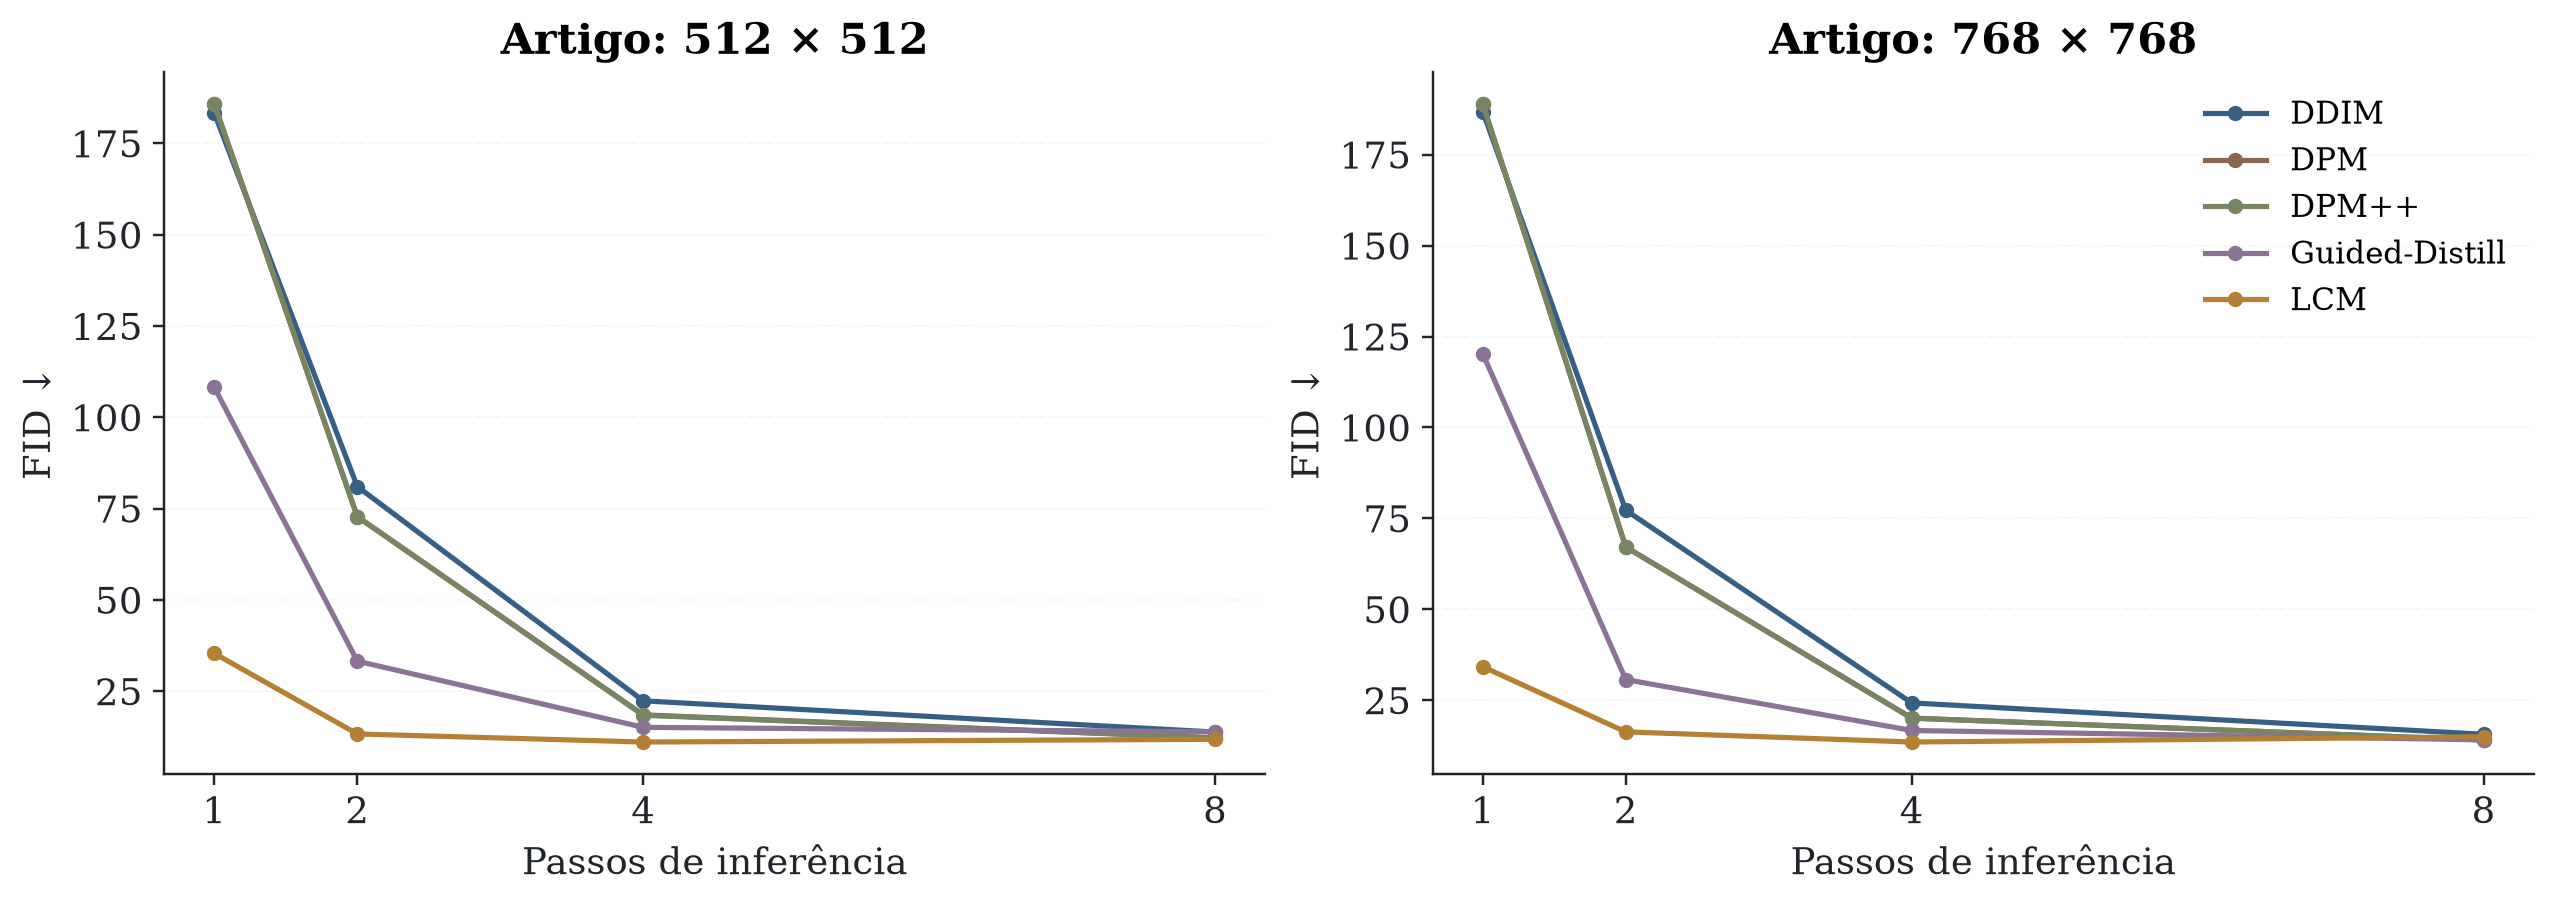

In [3]:
display(Image(filename=str(ROOT / 'assets/figures/paper_fid.png')))

Este gráfico é transcrição das Tabelas 1/2, não uma execução local em LAION.